# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import RwandaFieldBoundaryDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

2025-04-14 09:51:44,400 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Total number of patches: 342


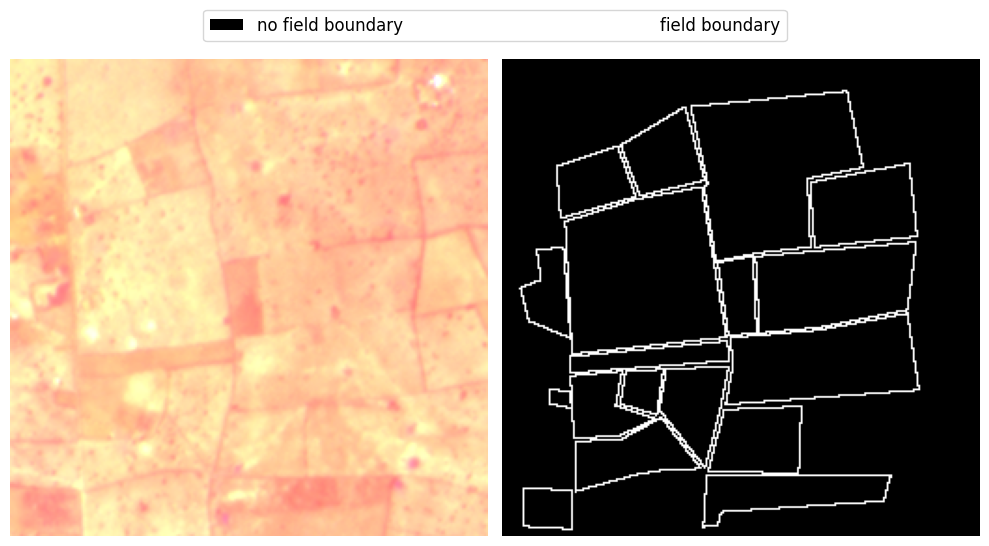

2025-04-14 09:51:44,611 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


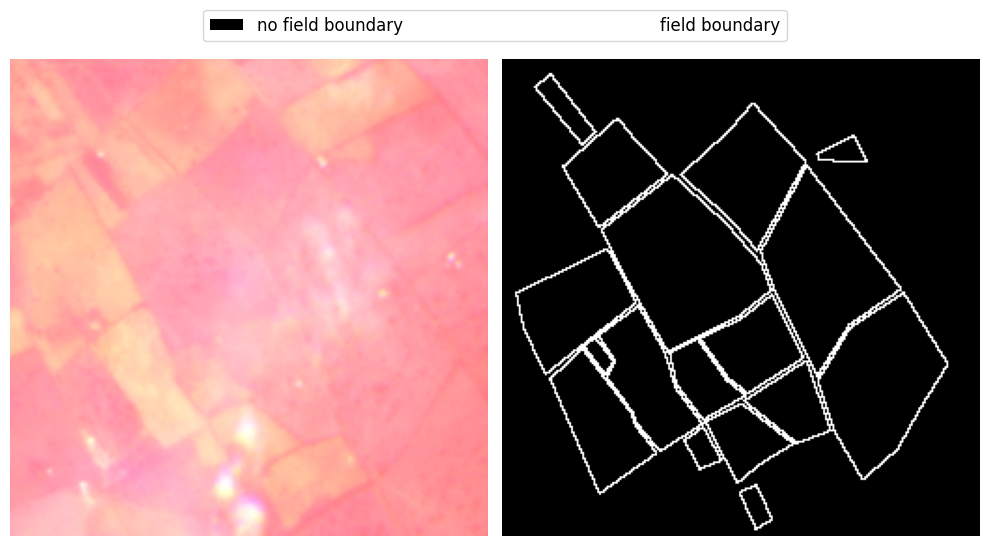

2025-04-14 09:51:44,803 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


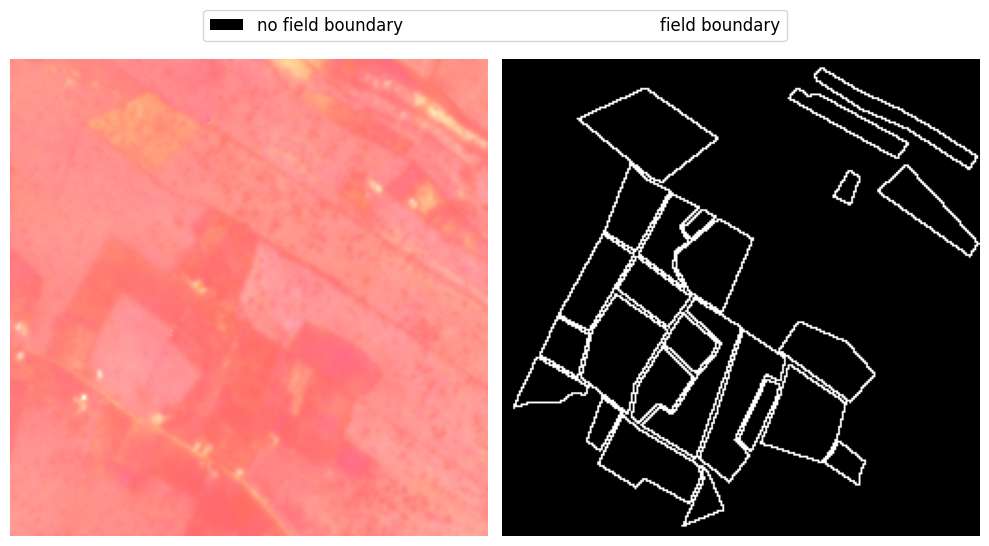

In [ ]:
dataset_config = {
    "data_dir": "./data/Rwanda_field_boundary/train"
}
dataset = RwandaFieldBoundaryDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(100);

In [48]:
dataset.data_distribution_table()

,Number of pixels
no field boundary,21247092.0
field boundary,1166220.0


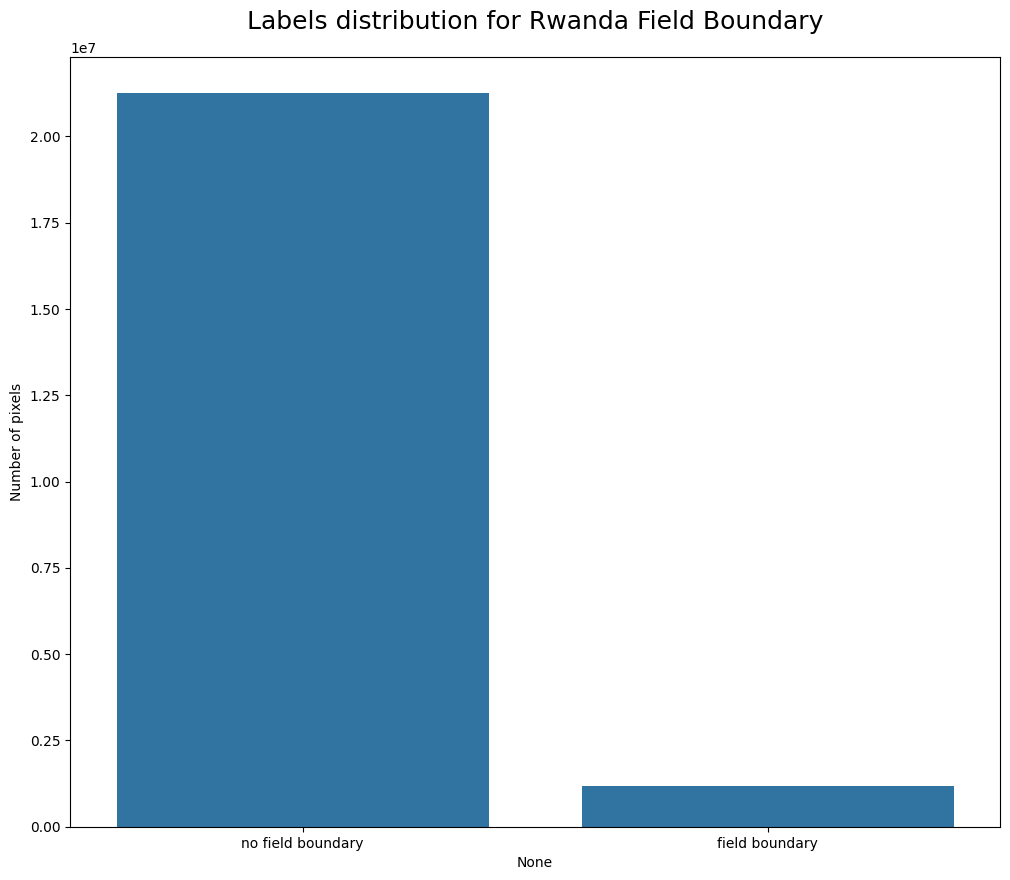

In [49]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Rwanda_field_boundary/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = RwandaFieldBoundaryDataset(train_dataset_config)
len(train_dataset)

342

## Create the model

In [ ]:
epochs = 100
model_directory = "./data/Rwanda_field_boundary"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [58]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-14 09:57:50,132 INFO Starting training.
training: 100%|██████████| 43/43 [00:03<00:00, 11.03it/s]
2025-04-14 09:57:54,128 INFO epoch: 1, time: 4, loss:  0.45097
testing on train set: 100%|██████████| 43/43 [00:01<00:00, 25.55it/s]
2025-04-14 09:57:57,817 INFO IOU:0.8858605961875058, IOU mean:0.4660172124953747, IOU per Class:[0.93203442 0.        ]
training: 100%|██████████| 43/43 [00:03<00:00, 11.27it/s]
2025-04-14 09:58:01,636 INFO epoch: 2, time: 4, loss:  0.34011
testing on train set: 100%|██████████| 43/43 [00:01<00:00, 27.08it/s]
2025-04-14 09:58:03,235 INFO IOU:0.7979348150083581, IOU mean:0.5004068765458193, IOU per Class:[0.91705714 0.08375661]
training: 100%|██████████| 43/43 [00:03<00:00, 11.21it/s]
2025-04-14 09:58:07,075 INFO epoch: 3, time: 4, loss:  0.29798
testing on train set: 100%|██████████| 43/43 [00:01<00:00, 26.49it/s]
2025-04-14 09:58:08,708 INFO IOU:0.7840402841909588, IOU mean:0.49006153157928806, IOU per Class:[0.89119814 0.08892492]
training: 100%|███

## Predictions

2025-04-14 10:07:28,062 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Rwanda_field_boundary/checkpoint.pth.tar
2025-04-14 10:07:28,449 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Rwanda_field_boundary/checkpoint.pth.tar at epoch 101
2025-04-14 10:07:28,494 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-04-14 10:07:28,599 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-04-14 10:07:28,689 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-04-14 10:07:28,784 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


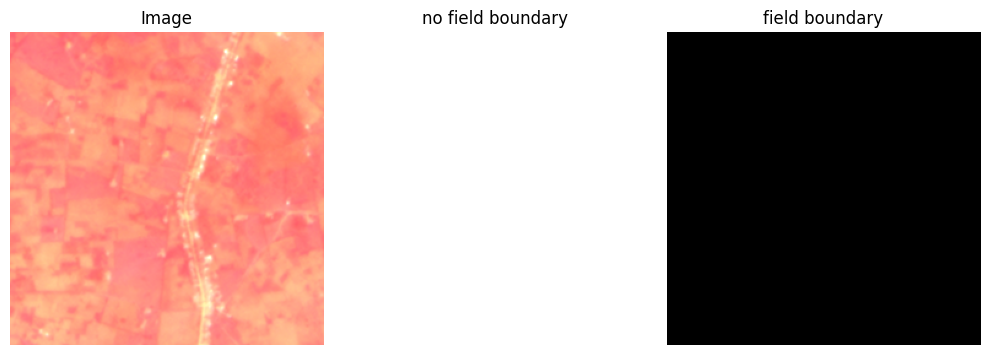

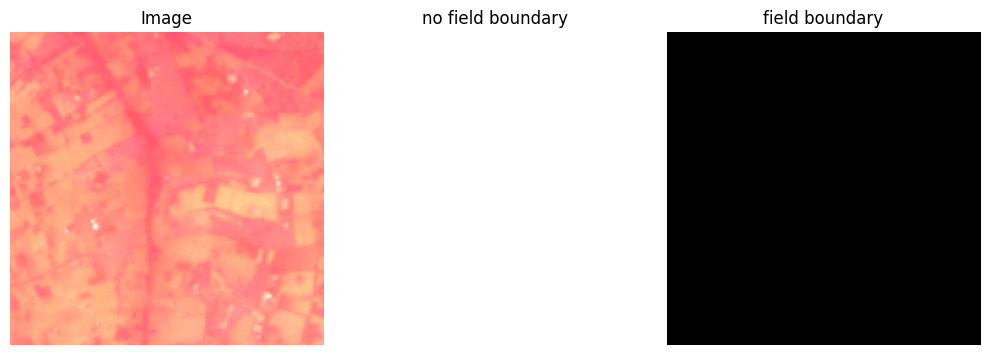

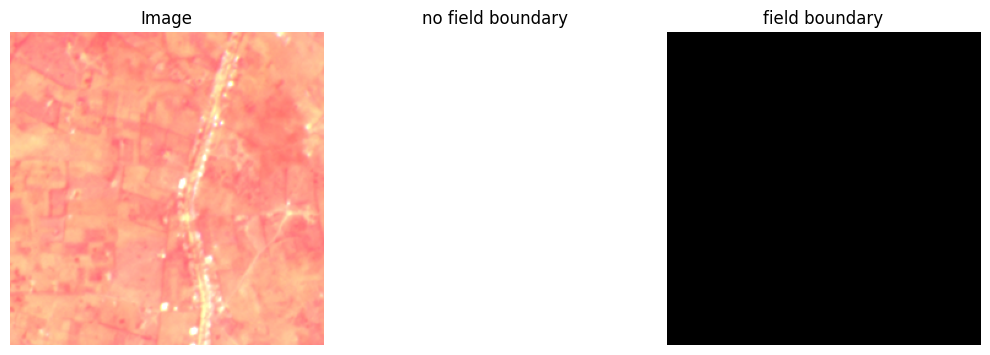

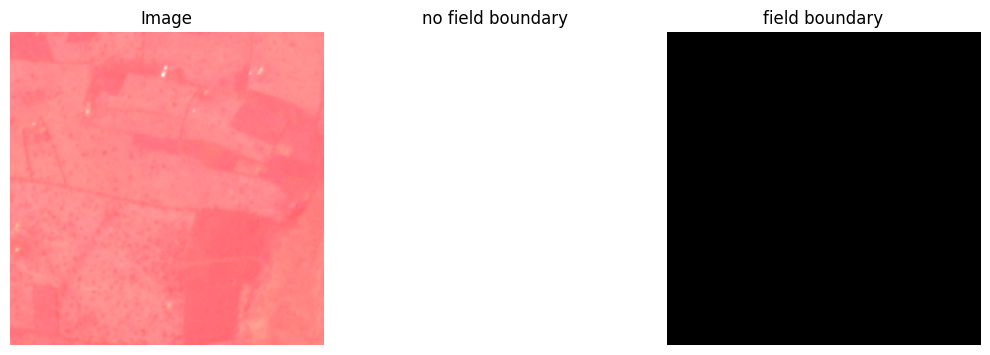

In [ ]:
model_path = "./data/Rwanda_field_boundary/checkpoint.pth.tar"
labels = ["no field boundary","field boundary"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

imageB02 = image_loader('./data/Rwanda_field_boundary/test/source/B02/2021_03_01_B02.tif')
imageB03 = image_loader('./data/Rwanda_field_boundary/test/source/B03/2021_03_01_B03.tif')
imageB04 = image_loader('./data/Rwanda_field_boundary/test/source/B04/2021_03_01_B04.tif')
image = np.dstack((imageB04,imageB03,imageB02))/1500
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('./data/Rwanda_field_boundary/test/source/B02/2021_03_06_B02.tif')
imageB03 = image_loader('./data/Rwanda_field_boundary/test/source/B03/2021_03_06_B03.tif')
imageB04 = image_loader('./data/Rwanda_field_boundary/test/source/B04/2021_03_06_B04.tif')
image = np.dstack((imageB04,imageB03,imageB02))/1500
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('./data/Rwanda_field_boundary/test/source/B02/2021_08_01_B02.tif')
imageB03 = image_loader('./data/Rwanda_field_boundary/test/source/B03/2021_08_01_B03.tif')
imageB04 = image_loader('./data/Rwanda_field_boundary/test/source/B04/2021_08_01_B04.tif')
image = np.dstack((imageB04,imageB03,imageB02))/1500
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('./data/Rwanda_field_boundary/test/source/B02/2021_11_03_B02.tif')
imageB03 = image_loader('./data/Rwanda_field_boundary/test/source/B03/2021_11_03_B03.tif')
imageB04 = image_loader('./data/Rwanda_field_boundary/test/source/B04/2021_11_03_B04.tif')
image = np.dstack((imageB04,imageB03,imageB02))/1500
fig = model.predict_masks(image, labels, transform)